In [1]:
import os
import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request
import warnings
warnings.filterwarnings("ignore")

from google.colab.output import eval_js

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (SparkSession.builder
         .appName("mit805-project-pt2")
         .config("spark.driver.memory", "6g")
         .getOrCreate())
spark

print(f"Spark Session Active: {spark.version}")

Spark Session Active: 4.0.4


In [2]:
print(eval_js("google.colab.kernel.proxyPort(4040)").rstrip("/") + "/jobs/")

https://4040-m-s-kkb-usw4a1-319bodqbixgzh-a.us-west4-1.prod.colab.dev/jobs/


## Download Months for Processing
January - April 2024

January - April 2025

In [3]:
os.makedirs("/content/data/raw", exist_ok=True)

study_months = ["2024-01", "2024-02", "2024-03", "2024-04",
                "2025-01", "2025-02", "2025-03", "2025-04"]

base_url = "https://d37ci6vzurychx.cloudfront.net/trip-data/"

months_per_period = len(study_months) // 2

for m in study_months:
    file_name = f"fhvhv_tripdata_{m}.parquet"
    file_path = "/content/data/raw/" + file_name
    if not os.path.exists(file_path):
        print("Downloading", file_name)
        urllib.request.urlretrieve(base_url + file_name, file_path + ".part")
        os.rename(file_path + ".part", file_path)

zone_path = "/content/data/taxi_zone_lookup.csv"
if not os.path.exists(zone_path):
    urllib.request.urlretrieve("https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv", zone_path)

## Validate Downloaded Data

In [4]:
def folder_size(folder):
    total = 0
    for root, dirs, files in os.walk(folder):
        for f in files:
            total += os.path.getsize(os.path.join(root, f))
    return total / 1e9

for f in sorted(os.listdir("/content/data/raw")):
    size_mb = os.path.getsize("/content/data/raw/" + f) / 1e6
    print(f"{f}: {size_mb:.0f} MB")

print(f"Raw study months: {folder_size('/content/data/raw'):.2f} GB")

fhvhv_tripdata_2024-01.parquet: 473 MB
fhvhv_tripdata_2024-02.parquet: 462 MB
fhvhv_tripdata_2024-03.parquet: 508 MB
fhvhv_tripdata_2024-04.parquet: 476 MB
fhvhv_tripdata_2025-01.parquet: 491 MB
fhvhv_tripdata_2025-02.parquet: 462 MB
fhvhv_tripdata_2025-03.parquet: 502 MB
fhvhv_tripdata_2025-04.parquet: 487 MB
Raw study months: 3.86 GB


## Data Cleaning

In [5]:
df_proc = spark.read.option("mergeSchema", "true").parquet("/content/data/raw/*.parquet")

clean_proc = df_proc.filter(
    (F.col("trip_miles") > 0) & (F.col("trip_miles") < 100) &
    (F.col("trip_time") > 0) & (F.col("trip_time") < 4 * 60 * 60) &
    (F.col("base_passenger_fare") > 0) & (F.col("base_passenger_fare") < 500) &
    (F.col("driver_pay") >= 0) &
    (F.col("dropoff_datetime") > F.col("pickup_datetime"))
)

cleaned_proc = (
    clean_proc
    .fillna(0, subset=["cbd_congestion_fee"])
    .withColumn("company", F.when(F.col("hvfhs_license_num") == "HV0003", "Uber")
                            .when(F.col("hvfhs_license_num") == "HV0005", "Lyft")
                            .otherwise("Other"))
    .withColumn("pickup_month", F.date_format("pickup_datetime", "yyyy-MM"))
    .withColumn("pickup_hour", F.hour("pickup_datetime"))
    .withColumn("pickup_day", F.date_format("pickup_datetime", "EEEE"))
    .withColumn("trip_minutes", F.col("trip_time") / 60))

clean_trips = cleaned_proc.filter(F.col("pickup_month").isin(study_months))

zones = spark.read.csv("/content/data/taxi_zone_lookup.csv", header=True, inferSchema=True)

## Post-cleaning Results

In [6]:
if not os.path.exists("/content/data/processing/_SUCCESS"):
    cleaned_proc.write.mode("overwrite").parquet("/content/data/processing")

print(f"Processing dataset: {folder_size('/content/data/processing'):.2f} GB")

n_raw = df_proc.count()
n_clean = spark.read.parquet("/content/data/processing").count()
print(f"Before cleaning: {n_raw:,} rows")
print(f"After cleaning:  {n_clean:,} rows")
print(f"Removed:         {n_raw - n_clean:,} rows ({(n_raw - n_clean) / n_raw:.2%})")

Processing dataset: 5.19 GB
Before cleaning: 160,072,893 rows
After cleaning:  159,922,576 rows
Removed:         150,317 rows (0.09%)


In [7]:
trips = spark.read.parquet("/content/data/processing")

trips = trips.withColumn("period", F.when(F.col("pickup_month")
                                    .startswith("2024"), "Before (2024)")
                                    .otherwise("After (2025)"))

print("Trips in the processing dataset:", f"{trips.count():,}")
trips.groupBy("period").count().show()

Trips in the processing dataset: 159,922,576
+-------------+--------+
|       period|   count|
+-------------+--------+
| After (2025)|79922296|
|Before (2024)|80000280|
+-------------+--------+



## Find the Charging Zone

In [8]:
zone_fee = (
    trips
    .filter(F.col("period") == "After (2025)")
    .groupBy("PULocationID")
    .agg(F.count("*").alias("trips"),
          F.sum(F.when(F.col("cbd_congestion_fee") > 0, 1).otherwise(0)).alias("trips_with_fee"))
    .withColumn("share_with_fee", F.round(F.col("trips_with_fee") / F.col("trips"), 3)))

zone_fee = (
    zone_fee
    .join(F.broadcast(zones), zone_fee.PULocationID == zones.LocationID)
    .select("PULocationID", "Borough", "Zone", "trips", "share_with_fee")
    .orderBy(F.desc("share_with_fee"))
    .toPandas())

zone_fee.head(50)

,PULocationID,Borough,Zone,trips,share_with_fee
0,161,Manhattan,Midtown Center,941440,0.974
1,162,Manhattan,Midtown East,627571,0.974
2,125,Manhattan,Hudson Sq,291053,0.972
3,163,Manhattan,Midtown North,647203,0.970
4,234,Manhattan,Union Sq,855287,0.970
5,113,Manhattan,Greenwich Village North,482318,0.970
6,230,Manhattan,Times Sq/Theatre District,950859,0.969
7,211,Manhattan,SoHo,451124,0.968
8,231,Manhattan,TriBeCa/Civic Center,896970,0.968
9,100,Manhattan,Garment District,426307,0.968


## Set threshold above entry where the steep drop in share_with_fee occurs

In [9]:
threshold = 0.75

cbd_zones = zone_fee[zone_fee["share_with_fee"] > threshold]["PULocationID"].tolist()
print(len(cbd_zones), "zones in the charging zone")
print(zone_fee[zone_fee["share_with_fee"] > threshold]["Borough"].value_counts())

38 zones in the charging zone
Borough
Manhattan    38
Name: count, dtype: int64


## Label every trip

In [10]:
trips = trips.withColumn(
    "area",
    F.when(F.col("PULocationID").isin(cbd_zones) | F.col("DOLocationID").isin(cbd_zones), "CBD")
     .otherwise("Outside CBD"))

trips.groupBy("period", "area").count().orderBy("period", "area").show()

+-------------+-----------+--------+
|       period|       area|   count|
+-------------+-----------+--------+
| After (2025)|        CBD|26618129|
| After (2025)|Outside CBD|53304167|
|Before (2024)|        CBD|27983637|
|Before (2024)|Outside CBD|52016643|
+-------------+-----------+--------+



## MapReduce by RDD

In [11]:
start_time = time.perf_counter()

cols = ["period", "area", "trip_miles", "trip_time", "base_passenger_fare", "driver_pay", "cbd_congestion_fee"]

trips_rdd = trips.select(cols).rdd

# MAP: one (key, value) pair per trip
mapped = trips_rdd.map(lambda r: ((r["period"], r["area"]),
    (1, r["trip_miles"], r["trip_time"] / 3600, r["base_passenger_fare"], r["driver_pay"], r["cbd_congestion_fee"])
))

# REDUCE: add two values together
def add_values(a, b):
    return (a[0] + b[0], a[1] + b[1], a[2] + b[2], a[3] + b[3], a[4] + b[4], a[5] + b[5])

reduced = mapped.reduceByKey(add_values)

elapsed = time.perf_counter() - start_time

print(f"Elapsed time: {elapsed:.4f} seconds \n")

print(reduced.toDebugString().decode())

Elapsed time: 0.4036 seconds 

(44) PythonRDD[83] at RDD at PythonRDD.scala:57 []
 |   MapPartitionsRDD[82] at mapPartitions at PythonRDD.scala:169 []
 |   ShuffledRDD[81] at partitionBy at NativeMethodAccessorImpl.java:0 []
 +-(44) PairwiseRDD[80] at reduceByKey at /tmp/ipykernel_4857/4157225029.py:16 []
    |   PythonRDD[79] at reduceByKey at /tmp/ipykernel_4857/4157225029.py:16 []
    |   MapPartitionsRDD[78] at javaToPython at NativeMethodAccessorImpl.java:0 []
    |   MapPartitionsRDD[77] at javaToPython at NativeMethodAccessorImpl.java:0 []
    |   SQLExecutionRDD[76] at javaToPython at NativeMethodAccessorImpl.java:0 []
    |   MapPartitionsRDD[75] at javaToPython at NativeMethodAccessorImpl.java:0 []
    |   MapPartitionsRDD[74] at javaToPython at NativeMethodAccessorImpl.java:0 []
    |   FileScanRDD[73] at javaToPython at NativeMethodAccessorImpl.java:0 []


In [12]:
start_time2 = time.perf_counter()

results = reduced.collect()

elapsed2 = time.perf_counter() - start_time2
print(f"Elapsed time: {elapsed2:.4f} seconds")

summary = pd.DataFrame(
    [(key[0], key[1]) + value for key, value in results],
    columns=["period", "area", "trips", "miles", "hours", "fare", "driver_pay", "cbd_fee"])

summary["trips_per_month"] = summary["trips"] / months_per_period
summary["avg_speed_mph"] = summary["miles"] / summary["hours"]
summary["avg_trip_miles"] = summary["miles"] / summary["trips"]
summary["avg_fare"] = summary["fare"] / summary["trips"]
summary["avg_driver_pay"] = summary["driver_pay"] / summary["trips"]
summary["avg_cbd_fee"] = summary["cbd_fee"] / summary["trips"]

summary = summary.sort_values(["area", "period"], ascending=[True, False])
summary[["period", "area", "trips_per_month", "avg_speed_mph", "avg_trip_miles",
         "avg_fare", "avg_driver_pay", "avg_cbd_fee"]].round(2)

Elapsed time: 1859.4280 seconds


,period,area,trips_per_month,avg_speed_mph,avg_trip_miles,avg_fare,avg_driver_pay,avg_cbd_fee
0,Before (2024),CBD,6995909.25,14.46,5.40,30.63,22.21,0.00
2,After (2025),CBD,6654532.25,15.15,5.51,33.00,23.00,1.44
1,Before (2024),Outside CBD,13004160.75,15.93,4.68,21.84,17.52,0.00
3,After (2025),Outside CBD,13326041.75,15.95,4.66,22.27,17.90,0.04


## MapReduce by DataFrame (comparison)

In [13]:
start_time3 = time.perf_counter()

df_summary = (
    trips
    .groupBy("period", "area")
    .agg(F.count("*").alias("trips"),
         F.sum("trip_miles").alias("miles"),
          (F.sum("trip_time") / 3600).alias("hours"),
         F.sum("base_passenger_fare").alias("fare"),
         F.sum("driver_pay").alias("driver_pay"),
         F.sum("cbd_congestion_fee").alias("cbd_fee")))

df_summary.explain(mode="formatted")

df_summary.orderBy("area", F.desc("period")).show()

elapsed3 = time.perf_counter() - start_time3
print(f"Elapsed time: {elapsed3:.4f} seconds")

== Physical Plan ==
AdaptiveSparkPlan (6)
+- HashAggregate (5)
   +- Exchange (4)
      +- HashAggregate (3)
         +- Project (2)
            +- Scan parquet  (1)


(1) Scan parquet 
Output [8]: [PULocationID#153, DOLocationID#154, trip_miles#155, trip_time#156L, base_passenger_fare#157, driver_pay#164, cbd_congestion_fee#170, pickup_month#172]
Batched: true
Location: InMemoryFileIndex [file:/content/data/processing]
ReadSchema: struct<PULocationID:int,DOLocationID:int,trip_miles:double,trip_time:bigint,base_passenger_fare:double,driver_pay:double,cbd_congestion_fee:double,pickup_month:string>

(2) Project
Output [7]: [trip_miles#155, trip_time#156L, base_passenger_fare#157, driver_pay#164, cbd_congestion_fee#170, CASE WHEN StartsWith(pickup_month#172, 2024) THEN Before (2024) ELSE After (2025) END AS period#177, CASE WHEN (PULocationID#153 INSET 100, 107, 113, 114, 12, 125, 13, 137, 144, 148, 158, 161, 162, 163, 164, 170, 186, 209, 211, 224, 229, 230, 231, 232, 233, 234, 246, 249, 

In [14]:
measures = ["trips_per_month", "avg_speed_mph", "avg_trip_miles", "avg_fare", "avg_driver_pay"]

before = summary[summary["period"] == "Before (2024)"].set_index("area")[measures]
after = summary[summary["period"] == "After (2025)"].set_index("area")[measures]

change = (after - before) / before * 100
change.loc["CBD minus Outside"] = change.loc["CBD"] - change.loc["Outside CBD"]
change.round(1)

,trips_per_month,avg_speed_mph,avg_trip_miles,avg_fare,avg_driver_pay
area,,,,,
CBD,-4.9,4.8,2.0,7.7,3.5
Outside CBD,2.5,0.1,-0.4,2.0,2.1
CBD minus Outside,-7.4,4.7,2.5,5.8,1.4


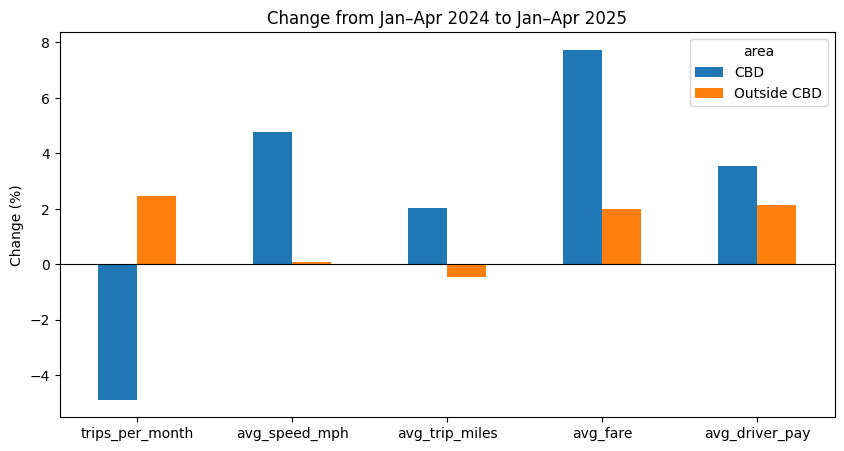

In [15]:
change.loc[["CBD", "Outside CBD"]].T.plot(kind="bar", figsize=(10, 5))
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Change from Jan–Apr 2024 to Jan–Apr 2025")
plt.ylabel("Change (%)")
plt.xticks(rotation=0)
plt.show()

In [16]:
hourly = (
    trips
    .groupBy("period", "area", "pickup_hour")
    .agg(F.count("*").alias("trips"),
          F.sum("trip_miles").alias("miles"),
          F.sum("trip_time").alias("seconds"))
    .toPandas())

hourly["avg_speed_mph"] = hourly["miles"] / (hourly["seconds"] / 3600)
hourly["trips_per_month"] = hourly["trips"] / months_per_period
hourly = hourly.sort_values("pickup_hour")

## Hourly Congestion Analysis

In [17]:
hourly = (
    trips
    .groupBy("period", "area", "pickup_hour")
    .agg(F.count("*").alias("trips"),
          F.sum("trip_miles").alias("miles"),
          F.sum("trip_time").alias("seconds"))
    .toPandas())

hourly["avg_speed_mph"] = hourly["miles"] / (hourly["seconds"] / 3600)
hourly["trips_per_month"] = hourly["trips"] / months_per_period
hourly = hourly.sort_values("pickup_hour")

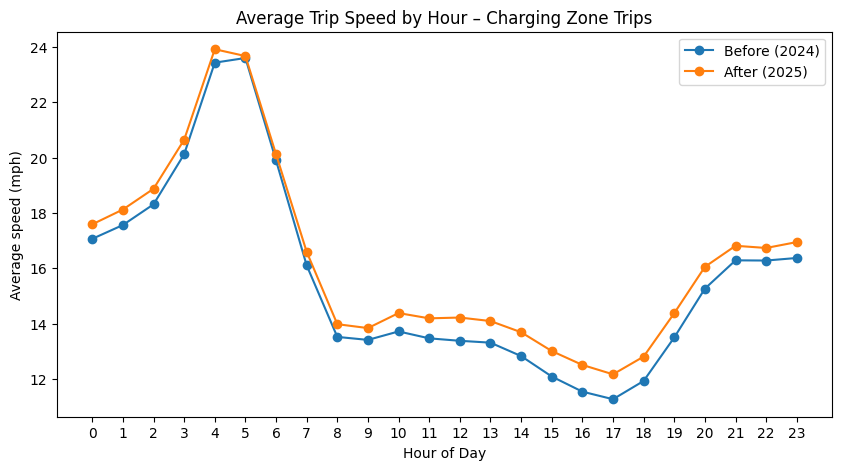

In [18]:
cbd_hourly = hourly[hourly["area"] == "CBD"]

plt.figure(figsize=(10, 5))
for period in ["Before (2024)", "After (2025)"]:
    d = cbd_hourly[cbd_hourly["period"] == period]
    plt.plot(d["pickup_hour"], d["avg_speed_mph"], marker="o", label=period)
plt.title("Average Trip Speed by Hour – Charging Zone Trips")
plt.xlabel("Hour of Day")
plt.ylabel("Average speed (mph)")
plt.xticks(range(0, 24))
plt.legend()
plt.show()

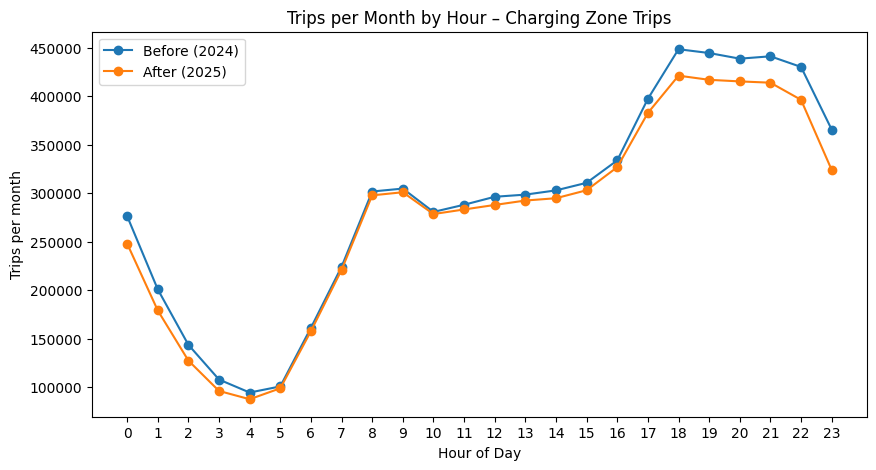

In [19]:
plt.figure(figsize=(10, 5))
for period in ["Before (2024)", "After (2025)"]:
    d = cbd_hourly[cbd_hourly["period"] == period]
    plt.plot(d["pickup_hour"], d["trips_per_month"], marker="o", label=period)
plt.title("Trips per Month by Hour – Charging Zone Trips")
plt.xlabel("Hour of Day")
plt.ylabel("Trips per month")
plt.xticks(range(0, 24))
plt.legend()
plt.show()

## Comparison with trips outside the charging zone

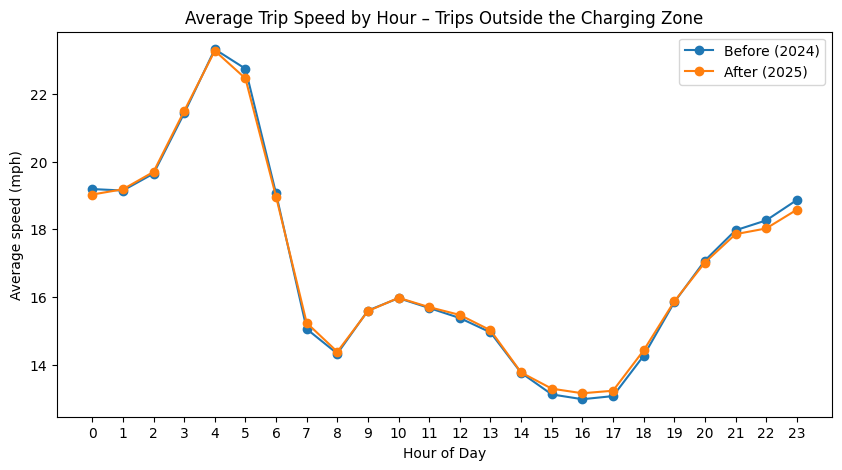

In [20]:
out_hourly = hourly[hourly["area"] == "Outside CBD"]

plt.figure(figsize=(10, 5))
for period in ["Before (2024)", "After (2025)"]:
    d = out_hourly[out_hourly["period"] == period]
    plt.plot(d["pickup_hour"], d["avg_speed_mph"], marker="o", label=period)
plt.title("Average Trip Speed by Hour – Trips Outside the Charging Zone")
plt.xlabel("Hour of Day")
plt.ylabel("Average speed (mph)")
plt.xticks(range(0, 24))
plt.legend()
plt.show()

## Save Results

In [21]:
from google.colab import drive
drive.mount("/content/drive")

os.makedirs("/content/drive/MyDrive/mit805_results", exist_ok=True)
summary.to_csv("/content/drive/MyDrive/mit805_results/summary_by_period_area.csv", index=False)
change.round(2).to_csv("/content/drive/MyDrive/mit805_results/change_before_after.csv")
hourly.to_csv("/content/drive/MyDrive/mit805_results/hourly_by_period_area.csv", index=False)
zone_fee.to_csv("/content/drive/MyDrive/mit805_results/zone_fee_share.csv", index=False)

Mounted at /content/drive
